<a href="https://colab.research.google.com/github/bil1980/-sistema_hospedagem_simples/blob/main/REVISAO_PLATAFORMA_A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [105]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler
from rapidfuzz import fuzz
from itertools import combinations

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
# DIAGNÓSTICO INICIAL
Dimensões do dataset:
Linhas: 13580
Colunas: 21

 Tipos de Dados:
Suburb            object
Address           object
Rooms              int64
Type              object
Price            float64
Method            object
SellerG           object
Date              object
Distance         float64
Postcode         float64
Bedroom2         float64
Bathroom         float64
Car              float64
Landsize         float64
BuildingArea     float64
YearBuilt        float64
CouncilArea       object
Lattitude        float64
Longtitude       float64
Regionname        object
Propertycount    float64
dtype: object

Quantidade de valores ausentes:
Suburb              0
Address             0
Rooms               0
Type                0
Price               0
Method              0
SellerG             0
Date                0
Distance            0
Postcode     

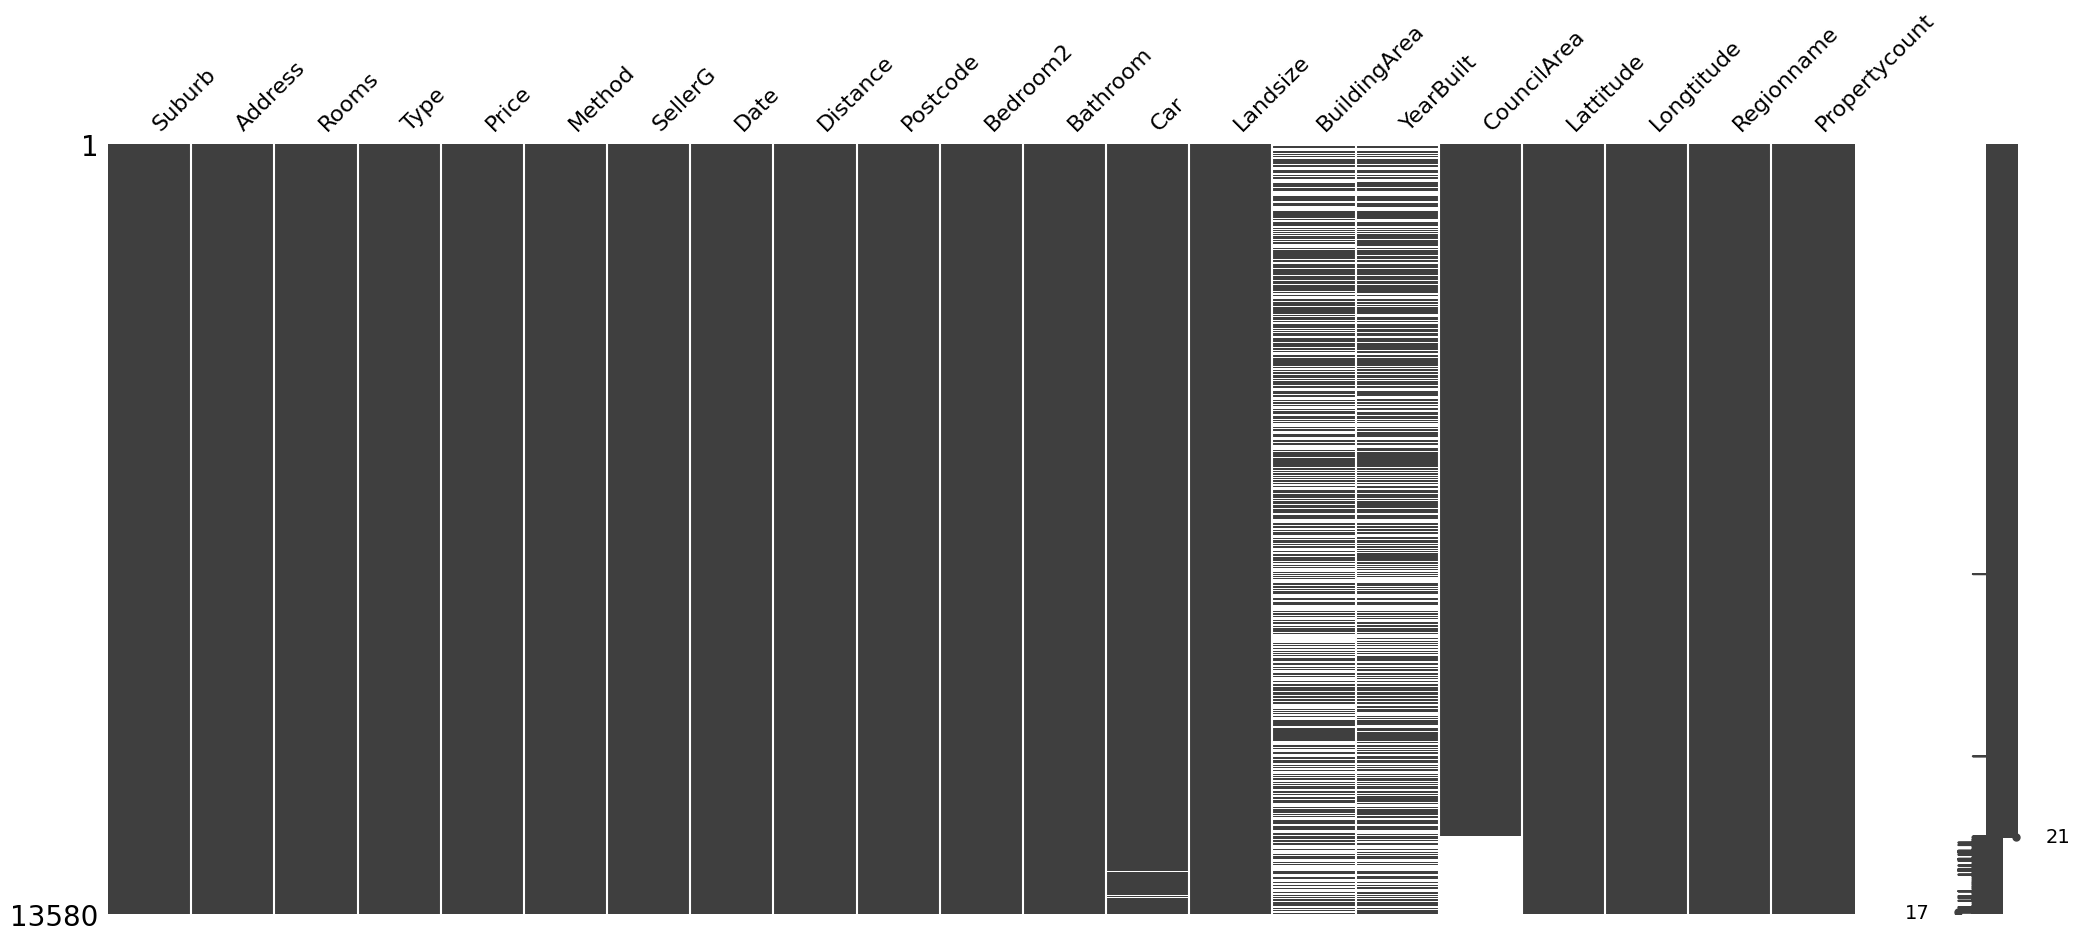


 AUSENCIAS NA MESMA LINHA


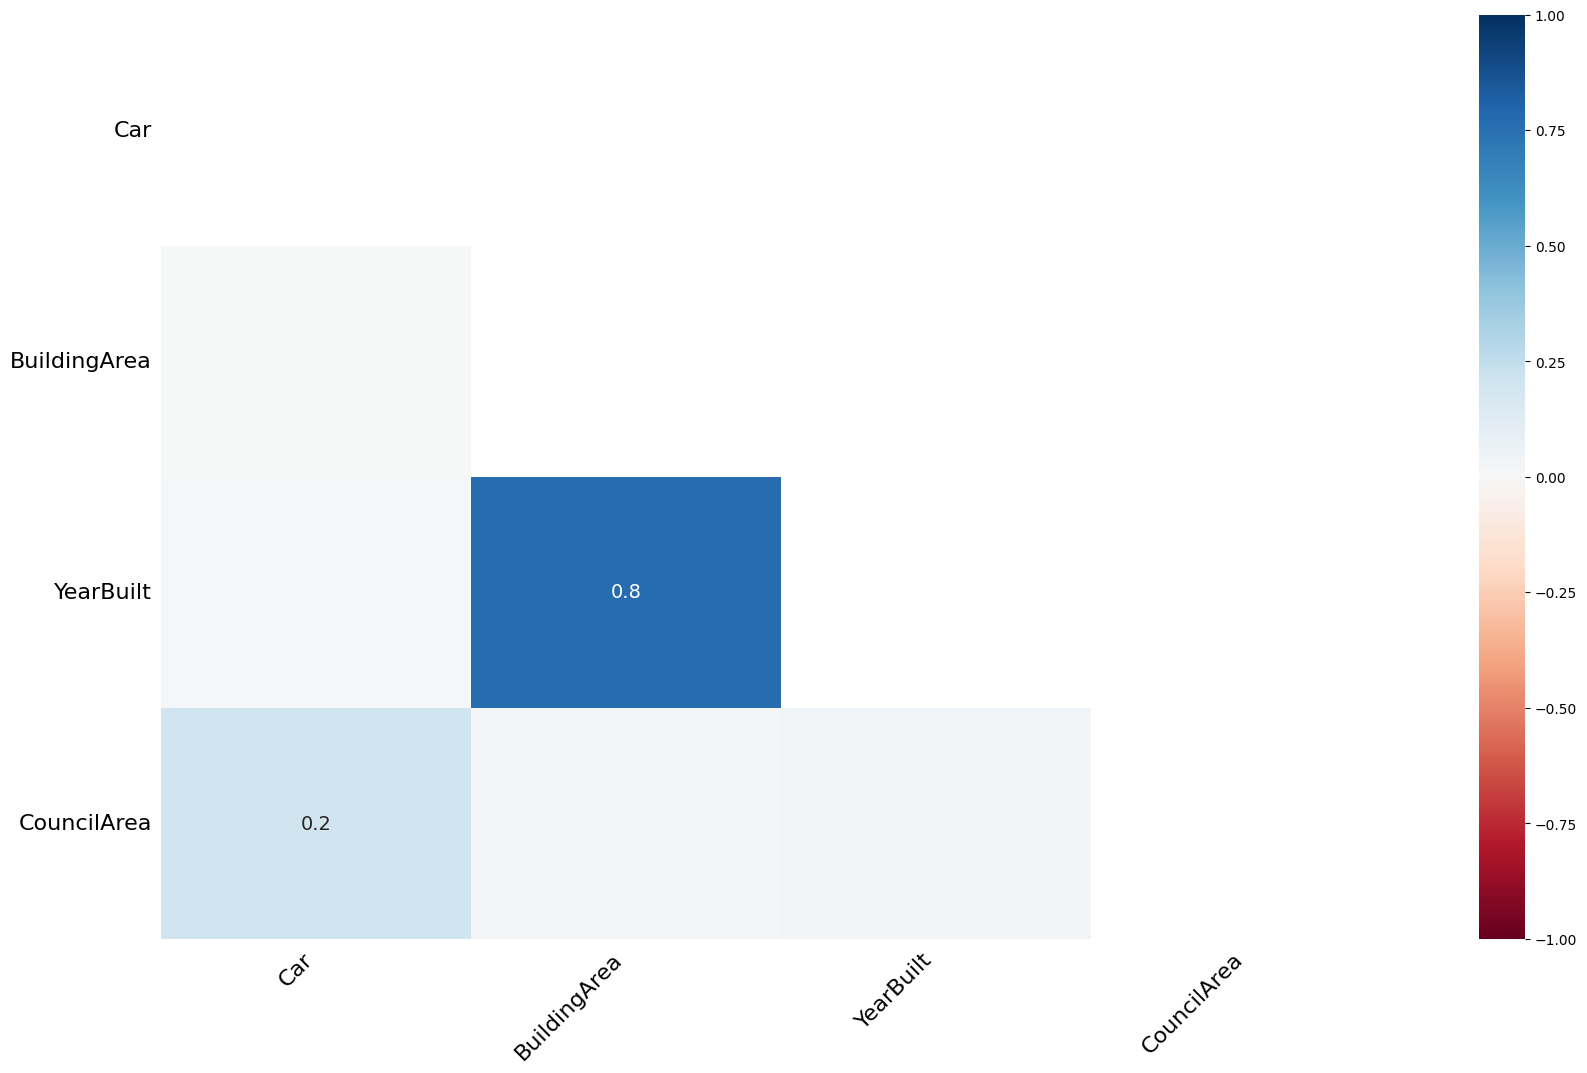

DataFrame após remover ausentes:


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0
6,Abbotsford,124 Yarra St,3,h,1876000.0,S,Nelson,7/05/2016,2.5,3067.0,...,2.0,0.0,245.0,210.0,1910.0,Yarra,-37.8024,144.9993,Northern Metropolitan,4019.0
7,Abbotsford,98 Charles St,2,h,1636000.0,S,Nelson,8/10/2016,2.5,3067.0,...,1.0,2.0,256.0,107.0,1890.0,Yarra,-37.8060,144.9954,Northern Metropolitan,4019.0


DataFrame após preencher ausentes:


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,126.0,1970.0,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,126.0,1970.0,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0



# COMPARAÇÃO ENTRE AS ESTRATÉGIAS

Linhas no DataFrame original: 13580

Linhas após remoção: 6196

Linhas após imputação: 13580


In [47]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno
import matplotlib.pyplot as plt

# CARREGAMENTO DOS DADOS
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv('/content/sample_data/melb_data.csv', sep = ',' )


# DIAGNÓSTICO INICIAL
print('# DIAGNÓSTICO INICIAL')
print("Dimensões do dataset:")
print("Linhas:", df.shape[0])
print("Colunas:", df.shape[1])

print("\n Tipos de Dados:")
print(df.dtypes)

print("\nQuantidade de valores ausentes:")
print(df.isnull().sum())

# RESUMO DE VALORES AUSENTES (QUANTIDADE E %)
print('\nRESUMO DE VALORES AUSENTES (QUANTIDADE E %)')
qtd_ausentes = df.isnull().sum()


pct_de_ausentes = ((df.isnull().sum() / len(df)) * 100)

resumo_ausentes = pd.DataFrame({'Quantidade ': qtd_ausentes, 'Porcentagem ' : pct_de_ausentes})

resumo_ausentes = resumo_ausentes.sort_values(
    by = 'Quantidade ',
    ascending=False
)

print(resumo_ausentes)

# VISUALIZAÇÃO DO PADRÃO DE AUSÊNCIA
print('\n# VISUALIZAÇÃO DO PADRÃO DE AUSÊNCIA')
print('\n PADRÃO DE AUSENCIA')
msno.matrix(df)
plt.show()

print('\n AUSENCIAS NA MESMA LINHA')
msno.heatmap(df)
plt.show()

# ESTRATÉGIA 1 — REMOÇÃO
df_remocao = df.dropna().copy()

print("DataFrame após remover ausentes:")
display(df_remocao.head())

# ESTRATÉGIA 2 — IMPUTAÇÃO
df_imputacao = df.copy()

colunas_numericas = df_imputacao.select_dtypes(
  include = 'number'
).columns

colunas_categoricas = df_imputacao.select_dtypes(
    include=['object', 'category']
).columns


df_imputacao[colunas_numericas] = df_imputacao[colunas_numericas].fillna(df_imputacao[colunas_numericas].median())

for coluna in colunas_categoricas:
    moda = df_imputacao[coluna].mode()

    if not moda.empty:
        df_imputacao[coluna] = df_imputacao[coluna].fillna(moda[0])

print("DataFrame após preencher ausentes:")
display(df_imputacao.head())


# COMPARAÇÃO ENTRE AS ESTRATÉGIAS
print('\n# COMPARAÇÃO ENTRE AS ESTRATÉGIAS')

print("\nLinhas no DataFrame original:", len(df))
print("\nLinhas após remoção:", len(df_remocao))
print("\nLinhas após imputação:", len(df_imputacao))




#DESAFIO

df = next(iter(dados_originais.values())).copy()

print(df.select_dtypes(include="number").columns.tolist())

import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler

# Escolher a coluna que queremos preencher
coluna_alvo = "price"  # Troque se necessário

# Converter a coluna para numérica
df[coluna_alvo] = pd.to_numeric(df[coluna_alvo], errors="coerce")

# Selecionar colunas numéricas relevantes
numericas = df.select_dtypes(include="number").columns.tolist()

# Evitar usar identificadores como se fossem características
auxiliares = [
    c for c in numericas
    if c != coluna_alvo
    and not any(p in c.lower() for p in ["id", "sku", "code", "codigo"])
]

colunas = [coluna_alvo] + auxiliares

# Remover colunas totalmente vazias
dados = df[colunas].dropna(axis=1, how="all")

if coluna_alvo not in dados.columns or len(dados.columns) < 2:
    raise ValueError(
        "É necessário ter a coluna-alvo e pelo menos outra "
        "coluna numérica com dados para usar o KNNImputer."
    )

# Guardar quais preços estavam ausentes originalmente
faltantes = dados[coluna_alvo].isna()

if faltantes.sum() == 0:
    print("A coluna escolhida não possui valores ausentes.")
else:
    # 1. Imputação estatística: mediana
    mediana = SimpleImputer(strategy="median")
    resultado_mediana = mediana.fit_transform(
        dados[[coluna_alvo]]
    ).ravel()

    # 2. KNNImputer: padronizar as escalas das colunas
    scaler = StandardScaler()
    dados_escalados = scaler.fit_transform(dados)

    knn = KNNImputer(n_neighbors=5, weights="distance")
    resultado_knn_escalado = knn.fit_transform(dados_escalados)

    # Recuperar a escala original dos valores
    resultado_knn = scaler.inverse_transform(
        resultado_knn_escalado
    )[:, dados.columns.get_loc(coluna_alvo)]

    # Comparar somente os valores que estavam ausentes
    comparacao = pd.DataFrame({
        "Valor original": dados.loc[faltantes, coluna_alvo],
        "Imputação pela mediana": resultado_mediana[faltantes],
        "Imputação pelo KNN": resultado_knn[faltantes]
    })

    display(comparacao.head(10))

    print("Quantidade de valores preenchidos:", faltantes.sum())
    print("Mediana utilizada:", round(
        dados[coluna_alvo].median(), 2
    ))
    print("Média dos valores imputados pela mediana:",
          round(comparacao["Imputação pela mediana"].mean(), 2))
    print("Média dos valores imputados pelo KNN:",
          round(comparacao["Imputação pelo KNN"].mean(), 2))


4. Aplique pelo menos duas estratégias de tratamento, guardando cada resultado em um
DataFrame separado (nunca altere o original):
a) remoção (de linhas ou de colunas — decida qual e justifique);
b) imputação por uma medida estatística adequada ao tipo da coluna.



A estratégia de remoção eliminou as linhas que continham valores ausentes, reduzindo o tamanho do dataset de 13580 para 6196 linhas. Já a imputação manteve as 13580 linhas originais.
Na remoção, a média e a mediana podem mudar porque alguns registros foram descartados.
Na imputação, os valores ausentes das colunas numéricas foram preenchidos com a mediana, enquanto os das colunas categóricas foram preenchidos com a moda. Isso preservou a quantidade de linhas,
mas pode ter alterado a distribuição dos dados, principalmente pela concentração de valores imputados em determinadas categorias ou valores numéricos.

** RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO**


 º1 - não existe uma regra fixa.
É necessário avaliar cada coluna antes de decidir entre imputar ou descartar,
evitando perder informações importantes ou criar resultados distorcidos.


 º2 - A média e a mediana podem dar valores diferentes para colunas como Price e Landsize,
pois essas variáveis podem ter valores muito altos ou muito baixos.
A mediana geralmente é mais segura para colunas como Price e Landsize, porque os preços dos imóveis e os tamanhos dos terrenos podem apresentar grande variação e valores extremos.


 º3 - A ausência de um valor pode ser útil quando ela representa alguma informação sobre o próprio dado ou sobre o processo de coleta.
 Por exemplo, no dataset de imóveis de Melbourne, se o campo BuildingArea estiver ausente, isso pode indicar que a área construída não foi informada ou medida.

 #DESAFIO

 O KNNImputer, da biblioteca scikit-learn, é uma técnica de imputação que utiliza os vizinhos mais próximos para estimar valores ausentes com base em outras características numéricas dos registros. Diferentemente da imputação pela média ou mediana, ele considera as semelhanças entre os dados.

Na comparação, a imputação pela mediana utiliza um único valor de referência para preencher os dados ausentes, enquanto o KNNImputer pode produzir estimativas diferentes para cada registro. Sua principal vantagem é considerar as características dos produtos, mas seu custo é maior em processamento e memória. Além disso, os resultados dependem da qualidade das variáveis utilizadas e da escolha dos vizinhos. Portanto, é importante comparar os resultados antes de decidir qual método é mais adequado.

In [107]:
caminho = '/content/KPMG_VI_New_raw_data_update_final.xlsx'

excel = pd.ExcelFile(caminho)
print(excel.sheet_names)

df = pd.read_excel(
    caminho,
    sheet_name='Transactions',
    header=1
)

# DUPLICATAS EXATAS
print('\n Duplicatas Exatas: ', df.duplicated().sum())

# DUPLICATAS POR SUBCONJUNTO DE COLUNAS
print('\n Duplicatas por transaction_id:', df.duplicated(subset=['transaction_id']).sum())

print('\n Duplicatas por transaction_id , customer_id e product_id:', df.duplicated(subset=['transaction_id', 'customer_id', 'product_id']).sum())

# UNICIDADE DOS IDENTIFICADORES

print('\n Quantidade de linhas:', len(df))

print('\n Quantidade de ids diferentes:', df['transaction_id'].nunique())

print('\n Quantidade de ids repetidos:', df['transaction_id'].duplicated().sum())

# DESAFIO



arquivo = "KPMG_VI_New_raw_data_update_final.xlsx"

df_transacoes = pd.read_excel(
    arquivo,
    sheet_name="Transactions",
    header=1
)

print("Total de registros:", len(df_transacoes))
print("Marcas diferentes:", df_transacoes["brand"].nunique())
df_transacoes = pd.read_excel(
    caminho,
    sheet_name="Transactions",
    header=1
)

print("Total de registros:", len(df_transacoes))
print("Marcas diferentes:", df_transacoes["brand"].nunique())

marcas = sorted(
    df_transacoes["brand"]
    .dropna()
    .astype(str)
    .str.strip()
    .unique()
)

pares = []

for marca1, marca2 in combinations(marcas, 2):
    similaridade = fuzz.ratio(marca1, marca2)

    pares.append({
        "Marca 1": marca1,
        "Marca 2": marca2,
        "Similaridade (%)": round(similaridade, 2)
    })

resultado_marcas = pd.DataFrame(pares)

display(
    resultado_marcas.sort_values(
        "Similaridade (%)",
        ascending=False
    ).reset_index(drop=True)
)

suspeitas = resultado_marcas[
    resultado_marcas["Similaridade (%)"] >= 60
].sort_values(
    "Similaridade (%)",
    ascending=False
)

display(suspeitas)

#DESAFIO 2

df_clientes = pd.read_excel(
    arquivo,
    sheet_name="CustomerDemographic"
)

print("Total de clientes:", len(df_clientes))
print("Colunas:", df_clientes.columns.tolist())


print("Quantidade de registros por gênero:")
display(
    df_clientes["gender"].value_counts(dropna=False).to_frame(
        name="Quantidade"
    )
)

print(
    "Quantidade de categorias diferentes:",
    df_clientes["gender"].nunique()
)

generos = df_clientes["gender"].dropna().astype(str)

generos_normalizados = (
    generos.str.strip().str.lower()
)

print("Valores originais:")
print(sorted(generos.unique()))

print("\nValores após normalização:")
print(sorted(generos_normalizados.unique()))

print("\nCategorias originais:", generos.nunique())
print(
    "Categorias após normalização:",
    generos_normalizados.nunique()
)



['Title Sheet', 'Transactions', 'NewCustomerList', 'CustomerDemographic', 'CustomerAddress']

 Duplicatas Exatas:  0

 Duplicatas por transaction_id: 0

 Duplicatas por transaction_id , customer_id e product_id: 0

 Quantidade de linhas: 20000

 Quantidade de ids diferentes: 20000

 Quantidade de ids repetidos: 0
Total de registros: 20000
Marcas diferentes: 6
Total de registros: 20000
Marcas diferentes: 6


,Marca 1,Marca 2,Similaridade (%)
0,Norco Bicycles,Trek Bicycles,74.07
1,Giant Bicycles,Trek Bicycles,66.67
2,Giant Bicycles,Norco Bicycles,64.29
3,OHM Cycles,Trek Bicycles,52.17
4,Giant Bicycles,OHM Cycles,50.00
5,Norco Bicycles,OHM Cycles,50.00
6,Norco Bicycles,Solex,31.58
7,Trek Bicycles,WeareA2B,28.57
8,OHM Cycles,Solex,26.67
9,Solex,Trek Bicycles,22.22


,Marca 1,Marca 2,Similaridade (%)
7,Norco Bicycles,Trek Bicycles,74.07
3,Giant Bicycles,Trek Bicycles,66.67
0,Giant Bicycles,Norco Bicycles,64.29


Total de clientes: 4000
Colunas: ['customer_id', 'name', 'gender', 'past_3_years_bike_related_purchases', 'DOB', 'age', 'job_title', 'job_industry_category', 'wealth_segment', 'deceased_indicator', 'owns_car', 'tenure']
Quantidade de registros por gênero:


,Quantidade
gender,
Female,2039
Male,1873
U,88


Quantidade de categorias diferentes: 3
Valores originais:
['Female', 'Male', 'U']

Valores após normalização:
['female', 'male', 'u']

Categorias originais: 3
Categorias após normalização: 3




 3º Verifique duplicatas por subconjunto de colunas: quais colunas, juntas, deveriam identificar
uma transação única? Escolha e justifique.


Verifiquei as duplicatas utilizando todas as colunas e também subconjuntos de colunas. Não foram encontradas duplicatas.
Escolhi transaction_id como principal identificador, pois ele representa uma transação específica. Também testei a combinação de transaction_id, product_id e customer_id para verificar se existiam registros repetidos referentes à mesma transação, produto e cliente.

4º  Investigue as colunas de identificação (como transaction_id): elas são realmente únicas?

Investiguei a coluna transaction_id utilizando a contagem de valores distintos e a verificação de duplicatas.
Como cada identificador aparece apenas uma vez, concluí que essa coluna é única nos dados.

5º Defina uma estratégia para os casos encontrados (remover, manter o registro mais recente,
consolidar informações...) e registre quantos registros foram afetados e qual o impacto em
pelo menos um indicador (ex.: soma de list_price).

A estratégia adotada foi remover apenas registros completamente duplicados, preservando os demais dados. Como não foram encontradas duplicatas exatas, nenhum registro foi removido. Portanto, a quantidade de registros e a soma de list_price permanecem inalteradas, resultando em impacto zero sobre esse indicador.




Para refletir
(responda com suas palavras, no notebook)

• Se o resultado de duplicatas exatas for zero, isso garante que não há registros repetidos?
Por quê?

Não. O resultado de duplicatas exatas igual a zero não garante que não existam registros repetidos. Isso apenas significa que não há linhas totalmente iguais. Ainda podem existir registros com o mesmo transaction_id ou com informações muito parecidas, mas com alguma diferença em outra coluna, como data, produto ou valor. Por isso, também é importante verificar duplicatas por colunas específicas.


• Em uma base de transações, duas linhas idênticas são sempre um erro? Dê um exemplo
em que não seriam.

Não. Duas linhas idênticas nem sempre são um erro. Por exemplo, duas pessoas podem comprar o mesmo produto, na mesma quantidade, pelo mesmo preço e na mesma data. As informações seriam iguais, mas poderiam representar duas compras diferentes.

•  Por que a escolha das colunas que definem "o mesmo registro" é uma decisão de negócio,
e não apenas técnica? Relacione com a etapa de Entendimento do Negócio do CRISP-DM.

A escolha das colunas é uma decisão de negócio porque depende de como a empresa entende e registra suas transações. Por exemplo, duas compras do mesmo cliente podem ter o mesmo produto e valor, mas serem compras diferentes. Na etapa de Entendimento do Negócio do CRISP-DM, é necessário compreender as regras e os objetivos da empresa para definir o que realmente caracteriza um registro duplicado e evitar excluir informações importantes.


#DESAFIO

Na planilha CustomerDemographic, encontrei três categorias distintas na coluna gender: Female, Male e U. A categoria Female aparece em 2.039 registros, Male em 1.873 e U em 88 registros.

Após normalizar os textos, removendo espaços extras e convertendo as letras para minúsculas, a quantidade de categorias continuou sendo três. Portanto, não foram encontradas variações causadas apenas por diferenças entre letras maiúsculas, minúsculas ou espaços.

A categoria U deve ser investigada antes de qualquer alteração, pois seu significado não deve ser presumido apenas pelo nome. Essa análise mostra a importância de verificar os valores reais antes de padronizar ou substituir categorias.

In [67]:

# NOMES DAS COLUNAS
colunas = [
    'age',
    'workclass',
    'fnlwgt',
    'education',
    'education_num',
    'marital_status',
    'occupation',
    'relationship',
    'race',
    'sex',
    'capital_gain',
    'capital_loss',
    'hours_per_week',
    'native_country',
    'income'
]
# CARREGAMENTO DOS DADOS
df = pd.read_csv('/content/sample_data/adult.data',
                 header=None,
                 names=colunas,
                 skipinitialspace=True)
# INSPEÇÃO DAS COLUNAS CATEGÓRICAS
colunas_categoricas = df.select_dtypes(
    include=['object']
).columns




for coluna in colunas_categoricas:

  print(f"\n Coluna: {coluna}")
  print(df[coluna].unique())



for coluna in colunas_categoricas:
    valores = df[coluna].dropna().astype(str)
    problema = valores[valores != valores.str.strip()]

    if not problema.empty:
        print(f"\nEspaços extras em {coluna}:")
        print(problema.unique())
    else:
        print(f"{coluna}: nenhum espaço extra encontrado.")


for coluna in colunas_categoricas:
    print(f"\n{coluna}:")
    print(sorted(df[coluna].dropna().astype(str).unique()))


print(df.isna().sum())
# PADRONIZAÇÃO DOS TEXTOS (ANTES x DEPOIS)
categorias_antes = df[colunas_categoricas].nunique(dropna=True)

df_padronizado = df.copy()

for coluna in colunas_categoricas:
    df_padronizado[coluna] = (
        df_padronizado[coluna]
        .astype('string')
        .str.strip()
    )
for coluna in colunas_categoricas:
    df_padronizado[coluna] = df_padronizado[coluna].str.lower()

categorias_depois = df_padronizado[colunas_categoricas].nunique(dropna=True)

comparacao = pd.DataFrame({
    'Categorias antes': categorias_antes,
    'Categorias depois': categorias_depois

# CONVERSÃO DOS MARCADORES DE AUSÊNCIA

ausentes = df.isna().sum()

print("Quantidade de valores ausentes por coluna:")
display(ausentes[ausentes > 0].to_frame(name='Valores ausentes'))

# ESCALONAMENTO — MIN-MAX


 from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

colunas_numericas = df.select_dtypes(include=['number']).columns.tolist()

print("Colunas numéricas:", colunas_numericas)

dados_numericos = df[colunas_numericas].copy()


for coluna in colunas_numericas:
    dados_numericos[coluna] = dados_numericos[coluna].fillna(
        dados_numericos[coluna].median()
    )

    minmax = MinMaxScaler()
dados_minmax = pd.DataFrame(
    minmax.fit_transform(dados_numericos),
    columns=colunas_numericas
)

    # ESCALONAMENTO — Z-SCORE

    zscore = StandardScaler()
dados_zscore = pd.DataFrame(
    zscore.fit_transform(dados_numericos),
    columns=colunas_numericas
)

    # ESCALONAMENTO — ROBUSTO

    robust = RobustScaler()
dados_robust = pd.DataFrame(
    robust.fit_transform(dados_numericos),
    columns=colunas_numericas
)

    # COMPARAÇÃO ENTRE AS TÉCNICA

    def resumir(dados, tecnica):
    resumo = dados.agg(['min', 'max', 'mean', 'std']).T
    resumo.columns = ['Mínimo', 'Máximo', 'Média', 'Desvio padrão']
    resumo.insert(0, 'Técnica', tecnica)
    return resumo

comparacao_escalonamento = pd.concat([
    resumir(dados_minmax, 'Min-Max'),
    resumir(dados_zscore, 'Z-score'),
    resumir(dados_robust, 'RobustScaler')
])

display(comparacao_escalonamento.round(3))

    import matplotlib.pyplot as plt

coluna = 'capital_gain'

plt.figure(figsize=(10, 5))
plt.boxplot([
    dados_numericos[coluna],
    dados_minmax[coluna],
    dados_zscore[coluna],
    dados_robust[coluna]
], tick_labels=[
    'Original',
    'Min-Max',
    'Z-score',
    'RobustScaler'
])

plt.title(f'Comparação do escalonamento: {coluna}')
plt.ylabel('Valor')
plt.grid(True, axis='y')
plt.show()


 Coluna: workclass
['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' 'Local-gov' '?'
 'Self-emp-inc' 'Without-pay' 'Never-worked']

 Coluna: education
['Bachelors' 'HS-grad' '11th' 'Masters' '9th' 'Some-college' 'Assoc-acdm'
 'Assoc-voc' '7th-8th' 'Doctorate' 'Prof-school' '5th-6th' '10th'
 '1st-4th' 'Preschool' '12th']

 Coluna: marital_status
['Never-married' 'Married-civ-spouse' 'Divorced' 'Married-spouse-absent'
 'Separated' 'Married-AF-spouse' 'Widowed']

 Coluna: occupation
['Adm-clerical' 'Exec-managerial' 'Handlers-cleaners' 'Prof-specialty'
 'Other-service' 'Sales' 'Craft-repair' 'Transport-moving'
 'Farming-fishing' 'Machine-op-inspct' 'Tech-support' '?'
 'Protective-serv' 'Armed-Forces' 'Priv-house-serv']

 Coluna: relationship
['Not-in-family' 'Husband' 'Wife' 'Own-child' 'Unmarried' 'Other-relative']

 Coluna: race
['White' 'Black' 'Asian-Pac-Islander' 'Amer-Indian-Eskimo' 'Other']

 Coluna: sex
['Male' 'Female']

 Coluna: native_country
['United-States' 'Cuba' 'Jam

Para refletir (responda com suas palavras, no notebook)
• Por que df.isna().sum() pode retornar zero em todas as colunas de um dataset que, na
verdade, tem dados faltando?

O df.isna().sum() pode retornar zero porque o pandas só reconhece como ausentes valores específicos, como NaN e None. Se os dados faltantes estiverem representados por outros símbolos, como ?, ou por textos como "desconhecido", ele não vai identificá-los automaticamente. Por isso, é necessário verificar os dados e converter esses marcadores para NaN antes de contar os valores ausentes.

• Na coluna capital-gain, a grande maioria dos valores é zero. Qual das três técnicas de
escalonamento é mais afetada por isso? Justifique observando seus resultados.

A técnica Min-Max é bastante afetada pela presença de muitos zeros e de poucos valores muito altos, pois utiliza o valor mínimo e o máximo para fazer a transformação. Assim, a maioria dos valores continua próxima de zero, enquanto os valores extremos ficam próximos de 1. O Z-score também é influenciado pelos valores extremos, pois utiliza a média e o desvio-padrão. Já o RobustScaler é menos afetado, porque utiliza a mediana e o intervalo interquartil. Como a maioria dos valores de capital_gain é zero, a mediana e os quartis podem ser iguais a zero, fazendo com que muitos valores transformados continuem em zero.



• Faz sentido escalonar todas as colunas numéricas? Pesquise o que a coluna fnlwgt
representa e discuta.


Não necessariamente faz sentido escalonar todas as colunas numéricas. A coluna fnlwgt representa o peso estatístico de cada pessoa na amostra, ou seja, uma estimativa de quantas pessoas da população ela representa. Escalonar essa coluna pode ser útil dependendo do modelo utilizado, mas é importante lembrar que ela tem um significado diferente de idade ou horas trabalhadas. Portanto, antes de escalonar, devemos analisar o significado de cada coluna e verificar se ela será útil para o modelo. Em alguns casos, fnlwgt pode ser mantida sem escalonamento ou até removida, dependendo do objetivo da análise.

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


x
Valores iguais a 0:  8
Valores negativos: 0
y
Valores iguais a 0:  7
Valores negativos: 0
z
Valores iguais a 0:  20
Valores negativos: 0
Outliers por coluna usando Z-score:
carat     439
depth     685
table     336
price    1206
x          43
y          34
z          55
dtype: int64

Total de registros com pelo menos um outlier:
2350
Outliers por coluna usando IQR:
carat    1889
depth    2545
table     605
price    3540
x          32
y          29
z          49
dtype: int64

Total de registros com pelo menos um outlier:
6416


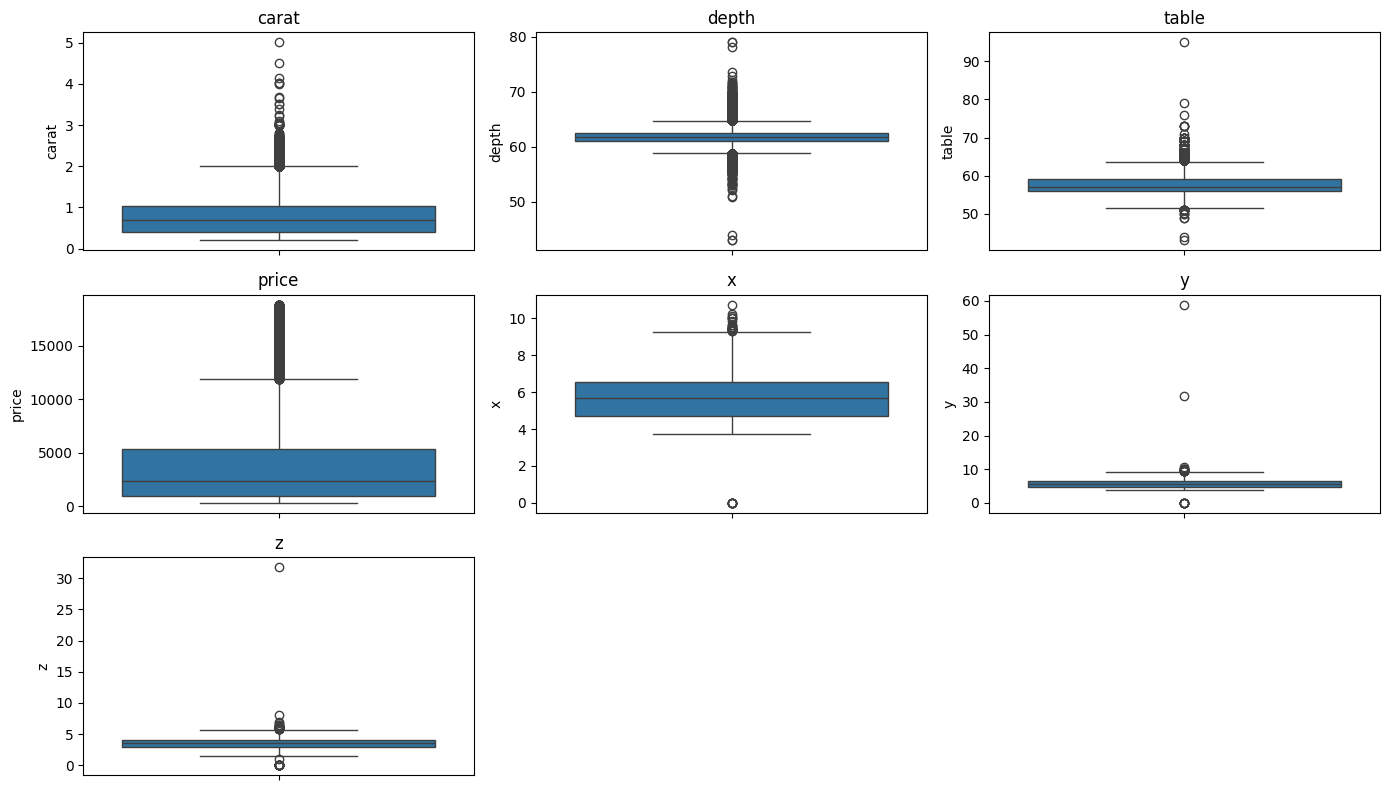

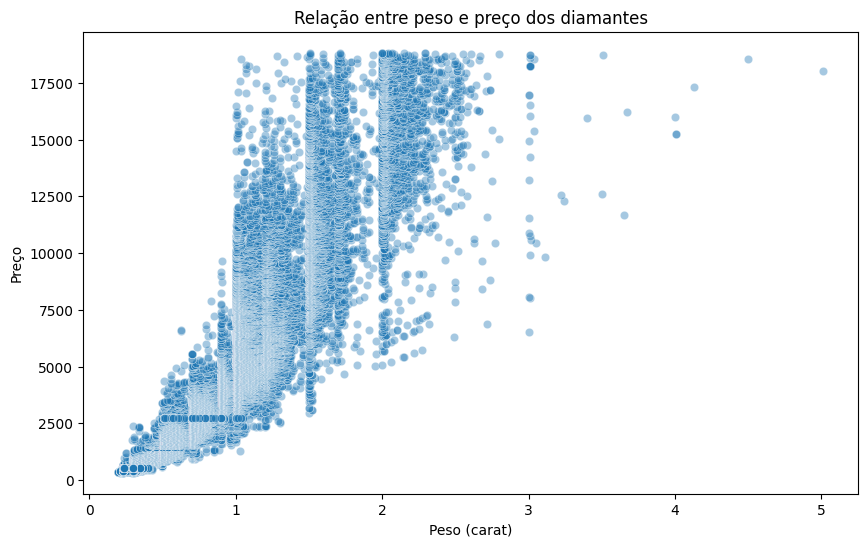

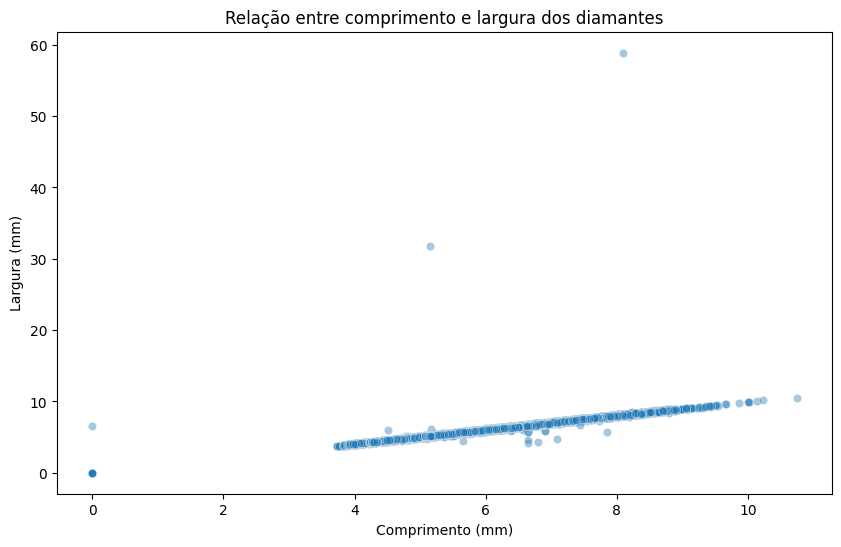

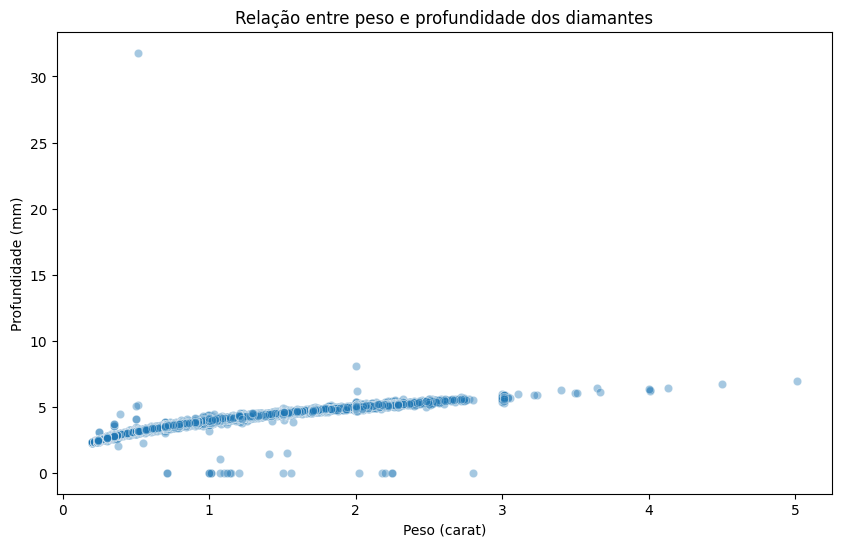

Limite inferior: -5611.375
Limite superior: 11885.625
Outliers encontrados: 3540
Limite inferior: -5611.375
Limite superior: 11885.625
Outliers encontrados: 3540
Registros originais: 53940
Após remoção: 50400
Após capping: 53940
Após transformação log: 53940


,Original,Remoção,Capping,Log
count,53940.00,50400.00,53940.00,53940.00
mean,3932.80,3159.46,3732.15,7.79
std,3989.44,2764.70,3436.77,1.01
min,326.00,326.00,326.00,5.79
25%,950.00,911.00,950.00,6.86
50%,2401.00,2155.00,2401.00,7.78
75%,5324.25,4669.00,5324.25,8.58
max,18823.00,11883.00,11885.62,9.84


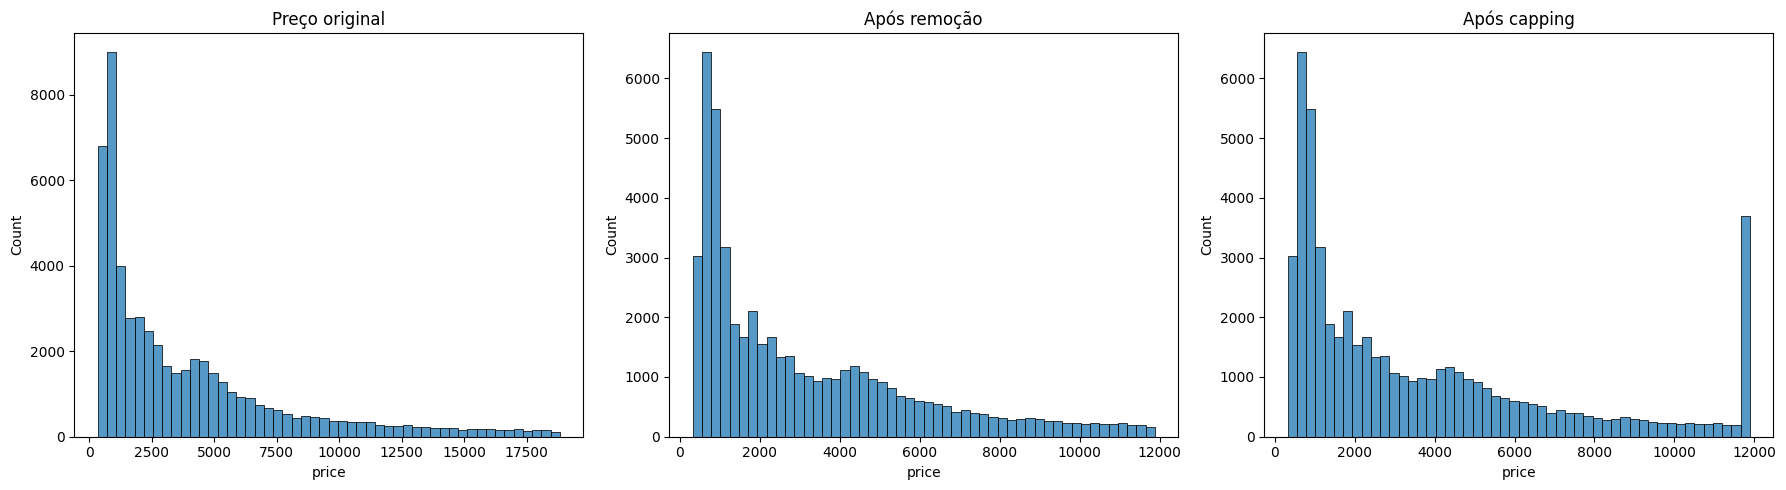

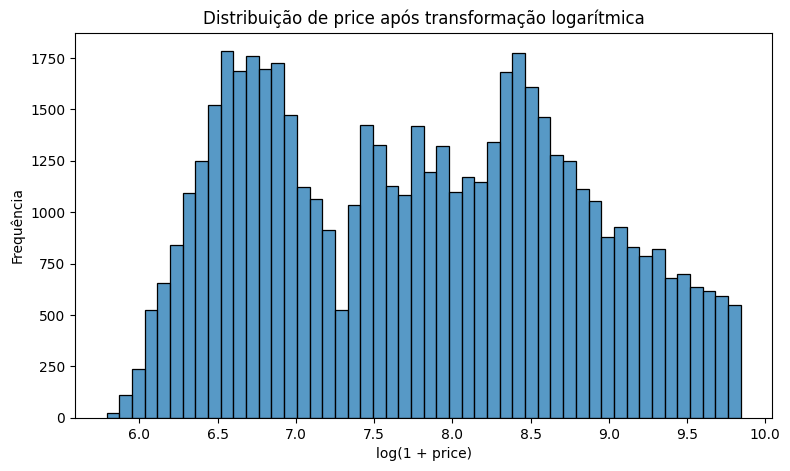

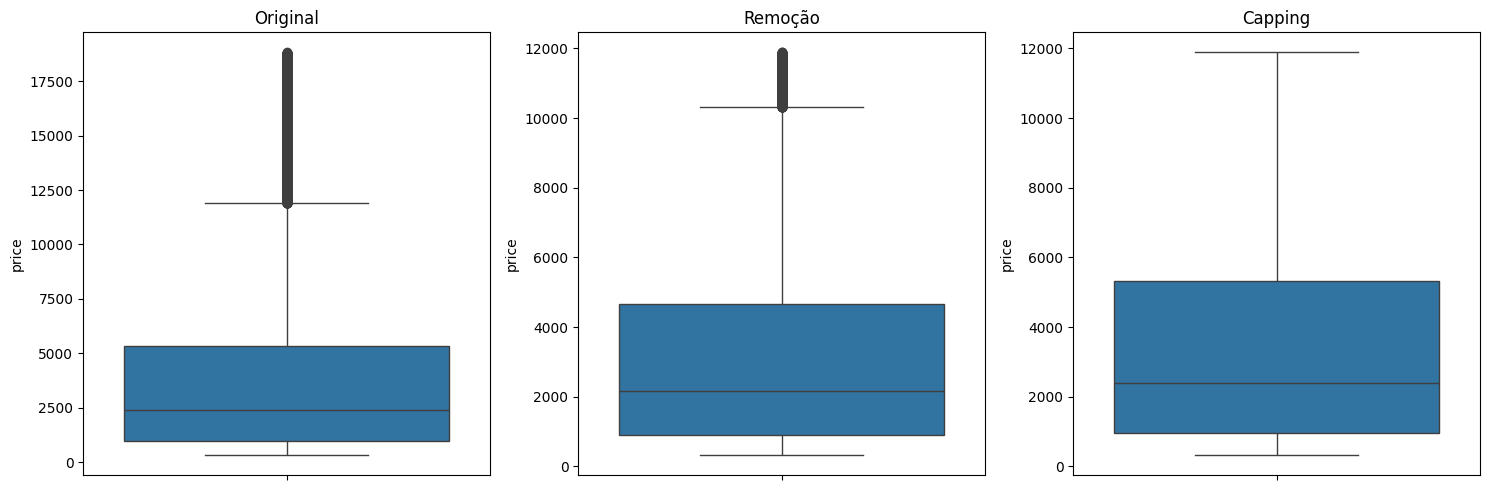

In [80]:
df = sns.load_dataset('diamonds')
# ESTATÍSTICAS DESCRITIVAS E VALORES IMPOSSÍVEIS
display(df.head())

df[['x','y','z']].describe()

for coluna in ['x','y','z'] :
  print(f"{coluna}")
  print('Valores iguais a 0: ', (df[coluna] == 0).sum())
  print("Valores negativos:", (df[coluna] <0).sum())

  # DETECÇÃO — Z-SCORE


colunas_numericas = df.select_dtypes(include='number').columns

z_scores = (
    (df[colunas_numericas] - df[colunas_numericas].mean())
    / df[colunas_numericas].std()
)

outliers_z = z_scores.abs() > 3

print("Outliers por coluna usando Z-score:")
print(outliers_z.sum())

print("\nTotal de registros com pelo menos um outlier:")
print(outliers_z.any(axis=1).sum())

# DETECÇÃO — IQR

Q1 = df[colunas_numericas].quantile(0.25)
Q3 = df[colunas_numericas].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers_iqr = (
    (df[colunas_numericas] < limite_inferior) |
    (df[colunas_numericas] > limite_superior)
)

print("Outliers por coluna usando IQR:")
print(outliers_iqr.sum())

print("\nTotal de registros com pelo menos um outlier:")
print(outliers_iqr.any(axis=1).sum())

# VISUALIZAÇÕES

colunas_numericas = df.select_dtypes(include='number').columns

plt.figure(figsize=(14, 8))

for i, coluna in enumerate(colunas_numericas, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[coluna])
    plt.title(coluna)

plt.tight_layout()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='carat',
    y='price',
    alpha=0.4
)

plt.title('Relação entre peso e preço dos diamantes')
plt.xlabel('Peso (carat)')
plt.ylabel('Preço')
plt.show()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='x',
    y='y',
    alpha=0.4
)

plt.title('Relação entre comprimento e largura dos diamantes')
plt.xlabel('Comprimento (mm)')
plt.ylabel('Largura (mm)')
plt.show()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='carat',
    y='z',
    alpha=0.4
)

plt.title('Relação entre peso e profundidade dos diamantes')
plt.xlabel('Peso (carat)')
plt.ylabel('Profundidade (mm)')
plt.show()

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Limite inferior:", limite_inferior)
print("Limite superior:", limite_superior)

print("Outliers encontrados:", (
    (df['price'] < limite_inferior) |
    (df['price'] > limite_superior)
).sum())

#TRATAMENTO — REMOÇÃO / CAPPING / TRANSFORMAÇÃO

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Limite inferior:", limite_inferior)
print("Limite superior:", limite_superior)

print("Outliers encontrados:", (
    (df['price'] < limite_inferior) |
    (df['price'] > limite_superior)
).sum())

# Estratégia 1: remoção dos registros com outliers em price
df_remocao = df[
    (df['price'] >= limite_inferior) &
    (df['price'] <= limite_superior)
].copy()

# Estratégia 2: capping — substituição pelos limites do IQR
df_capping = df.copy()

df_capping['price'] = df_capping['price'].clip(
    lower=limite_inferior,
    upper=limite_superior
)

# Estratégia 3: transformação logarítmica
df_log = df.copy()

df_log['price'] = np.log1p(df_log['price'])

print("Registros originais:", len(df))
print("Após remoção:", len(df_remocao))
print("Após capping:", len(df_capping))
print("Após transformação log:", len(df_log))

estatisticas = pd.DataFrame({
    'Original': df['price'].describe(),
    'Remoção': df_remocao['price'].describe(),
    'Capping': df_capping['price'].describe(),
    'Log': df_log['price'].describe()
})

display(estatisticas.round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['price'], bins=50, ax=axes[0])
axes[0].set_title('Preço original')

sns.histplot(df_remocao['price'], bins=50, ax=axes[1])
axes[1].set_title('Após remoção')

sns.histplot(df_capping['price'], bins=50, ax=axes[2])
axes[2].set_title('Após capping')

plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))

sns.histplot(df_log['price'], bins=50)

plt.title('Distribuição de price após transformação logarítmica')
plt.xlabel('log(1 + price)')
plt.ylabel('Frequência')
plt.show()

# COMPARAÇÃO ENTRE AS ESTRATÉGIAS

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(y=df['price'], ax=axes[0])
axes[0].set_title('Original')

sns.boxplot(y=df_remocao['price'], ax=axes[1])
axes[1].set_title('Remoção')

sns.boxplot(y=df_capping['price'], ax=axes[2])
axes[2].set_title('Capping')

plt.tight_layout()
plt.show()

# RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO
print('\n# RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO')

sns.histplot(df['price'], bins=50, kde=True)
plt.title('Distribuição dos preços dos diamantes')
plt.xlabel('Preço')
plt.ylabel('Frequência')
plt.show()

1. Carregue o dataset e analise as estatísticas descritivas das colunas numéricas. Consulte o
significado das colunas x, y e z. Algum valor é fisicamente impossível?

As colunas x, y e z representam, respectivamente, o comprimento, a largura e a profundidade dos diamantes, medidas em milímetros. Ao analisar as estatísticas descritivas, é possível identificar valores fisicamente impossíveis, como dimensões iguais a zero ou negativas, pois um diamante precisa ter dimensões positivas. Esses registros podem indicar erros nos dados e devem ser investigados antes de utilizar o dataset em análises ou modelos de aprendizado de máquina.

4. Classifique o que você encontrou: o que é erro de registro e o que é valor extremo legítimo?
Explique o critério usado.

Os boxplots permitem identificar possíveis outliers nas colunas numéricas, destacando valores que ficam fora dos limites dos
bigodes. Os gráficos de dispersão ajudam a analisar relações entre variáveis, como peso e preço, comprimento e largura e peso e profundidade.

Nos gráficos, pontos muito distantes da concentração principal podem indicar valores extremos ou inconsistências. Entretanto, nem todo outlier é um erro: alguns diamantes podem apresentar características legítimas incomuns. Por isso, os valores identificados devem ser analisados antes de decidir se precisam ser corrigidos ou removidos.

Para refletir (responda com suas palavras, no notebook)
• O Z-score parte de uma suposição sobre a forma da distribuição. Qual? Essa suposição vale
para price? Mostre com um gráfico.

O Z-score funciona melhor quando os dados seguem aproximadamente uma distribuição normal, em formato de sino e relativamente simétrica. A coluna price não apresenta esse formato, pois possui assimetria à direita: há muitos diamantes com preços menores e poucos com preços muito altos.





• Um diamante de mais de 4 quilates é um outlier a ser removido ou um diamante raro?
Como o objetivo da análise muda essa resposta?

Um diamante com mais de 4 quilates pode ser um diamante raro, e não necessariamente um erro. Se o objetivo for preparar dados para um modelo de previsão de preços, podemos manter esse registro, pois ele representa uma característica real do mercado. Porém, se o objetivo for estudar o comportamento dos diamantes mais comuns, podemos analisar esses valores separadamente para evitar que influenciem excessivamente algumas estatísticas.


• Dê um exemplo de situação em que remover outliers esconderia exatamente aquilo que o
negócio quer descobrir

Em uma joalheria, remover os diamantes mais caros como se fossem outliers poderia esconder justamente os produtos mais valiosos e raros do estoque. Isso prejudicaria uma análise sobre quais características fazem determinados diamantes alcançar preços elevados. Por isso, antes de remover outliers, é importante entender o objetivo da análise e verificar se os valores extremos são erros ou informações importantes.

Arquivos encontrados:
us-shein-appliances-3987.csv
us-shein-pet_supplies-4083.csv

Arquivo: us-shein-appliances-3987.csv
Dimensões: (3986, 8)


,goods-title-link--jump,goods-title-link--jump href,rank-title,rank-sub,price,discount,selling_proposition,goods-title-link
0,1pc Rechargeable Deep Tissue Muscle Handheld M...,https://us.shein.com/1pc-Rechargeable-Deep-Tis...,#1 Best Sellers,in Give Gifts,$2.03,-22%,NaN,NaN
1,1pc Portable Hanging Neck Fan,https://us.shein.com/1pc-Portable-Hanging-Neck...,#4 Best Sellers,in Top rated in Portable Fans,$6.48,-20%,NaN,NaN
2,1pc Pink Colored Curved Eyelash Curler False E...,https://us.shein.com/1pc-Pink-Colored-Curved-E...,NaN,NaN,$1.80,NaN,400+ sold recently,NaN



Arquivo: us-shein-pet_supplies-4083.csv
Dimensões: (4082, 11)


,goods-title-link--jump,goods-title-link--jump href,selling_proposition,price,blackfridaybelts-bg src,blackfridaybelts-content,rank-title,rank-sub,discount,color-count,goods-title-link
0,"Pet Shampoo Brush, Silicone Massage Rubber Bat...",https://us.shein.com/Pet-Shampoo-Brush-Silicon...,10k+ sold recently,$1.70,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1pc Fun Interactive Dog Toy - Cigar Shaped Plu...,https://us.shein.com/1pc-Fun-Interactive-Dog-T...,NaN,$2.05,https://img.ltwebstatic.com/images3_ccc/2023/1...,Save $0.45,#7 Best Sellers,in Pet Supplies,-18%,NaN,NaN
2,1pc Silicone Paw Detail Pet Placemat,https://us.shein.com/1pc-Silicone-Paw-Detail-P...,50+ sold recently,$3.98,https://img.ltwebstatic.com/images3_ccc/2023/1...,Save $1.32,NaN,NaN,-25%,6.0,NaN



===== DIAGNÓSTICO: us-shein-appliances-3987.csv =====

Dimensões:
(3986, 8)

Tipos das colunas:
goods-title-link--jump         object
goods-title-link--jump href    object
rank-title                     object
rank-sub                       object
price                          object
discount                       object
selling_proposition            object
goods-title-link               object
dtype: object

Valores ausentes por coluna:
goods-title-link--jump         3946
goods-title-link--jump href    3946
rank-title                     3427
rank-sub                       3427
price                             0
discount                       1527
selling_proposition            2625
goods-title-link                 40
dtype: int64

Duplicatas completas:
209

Percentual de células ausentes:
59.39%

Valores únicos das colunas de texto:

goods-title-link--jump:
['1pc Rechargeable Deep Tissue Muscle Handheld Massage Gun, Suitable For Body, Back And Neck Pain, Ultra-Compact Elegant Des

...

,Coluna,Limite inferior,Limite superior,Quantidade de outliers
0,price,-3.775,11.865,543
1,discount,-60.000,4.000,75
2,color-count,1.000,9.000,49



Comparação: us-shein-appliances-3987.csv


,Antes,Depois
Número de linhas,3986,3777
Número de colunas,8,9
% de células ausentes,59.39,57.1
Duplicatas completas,209,0
Tipos das colunas,goods-title-link--jump: object; goods-title-li...,goods-title-link--jump: string; goods-title-li...



Comparação: us-shein-pet_supplies-4083.csv


,Antes,Depois
Número de linhas,4082,3946
Número de colunas,11,12
% de células ausentes,56.24,53.75
Duplicatas completas,136,0
Tipos das colunas,goods-title-link--jump: object; goods-title-li...,goods-title-link--jump: string; goods-title-li...


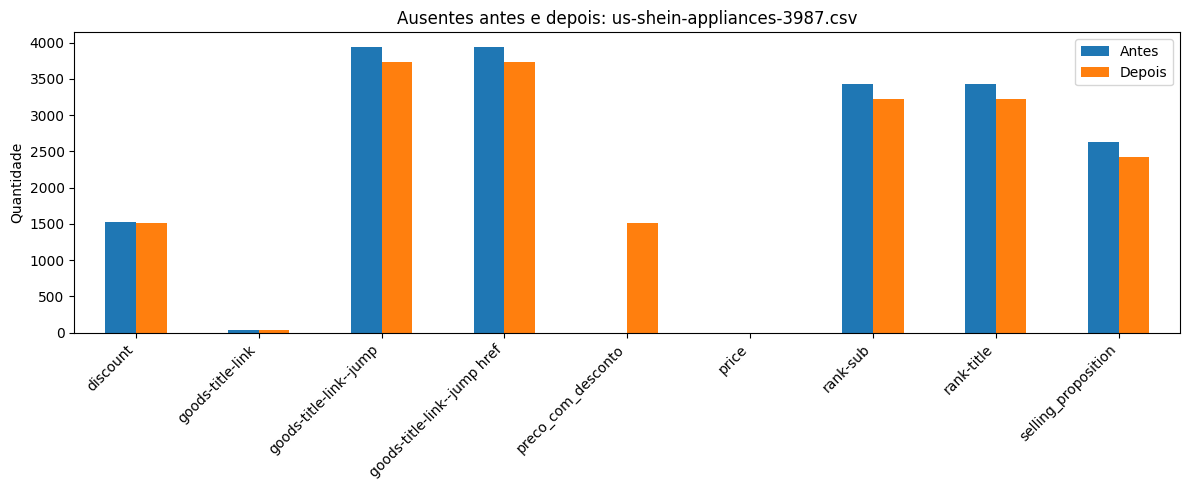

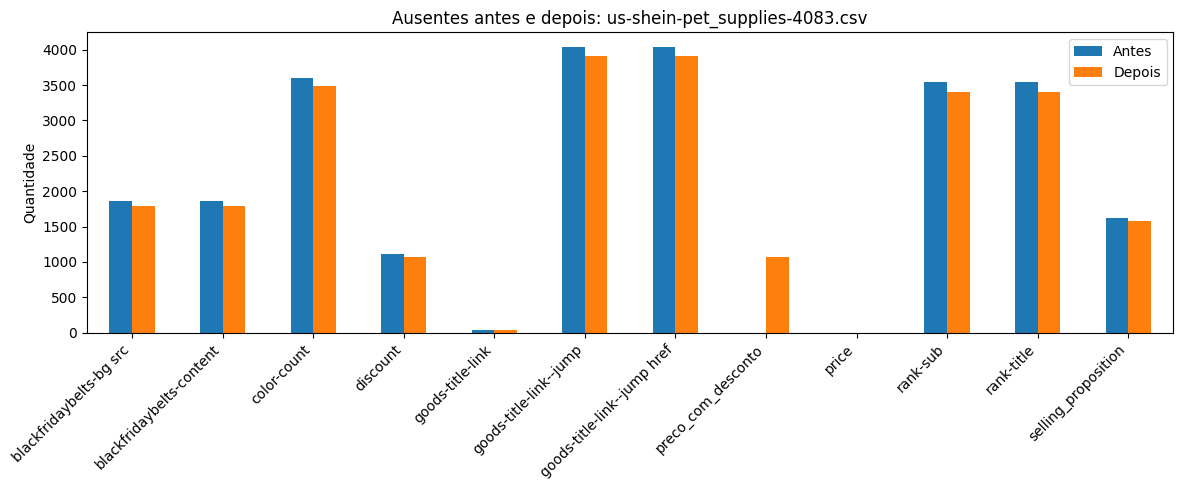

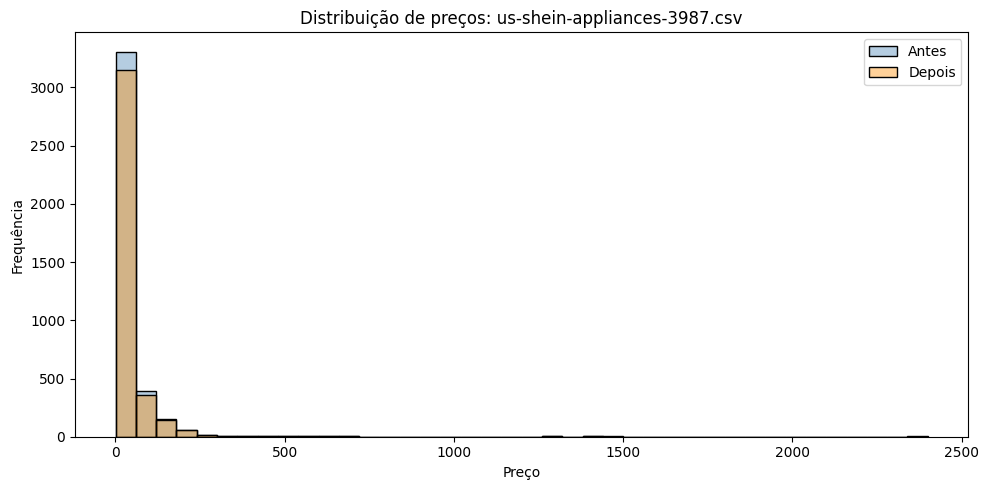

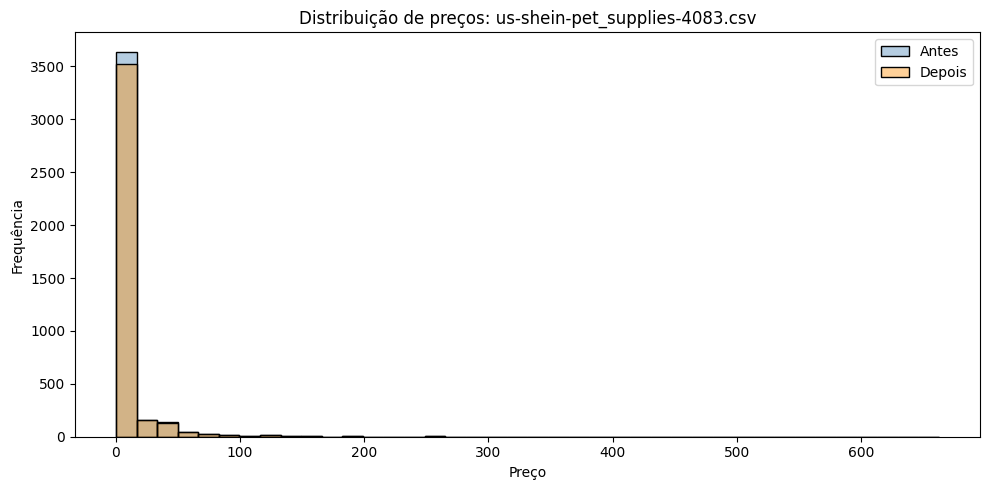

In [98]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno
import glob
import re
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler

# PERGUNTA DE NEGÓCIO
# Quais características dos produtos estão associadas a preços mais altos e descontos maiores na loja SHEIN
# A análise dos preços, descontos e categorias dos produtos pode ajudar a identificar padrões comerciais e orientar decisões de precificação.

# CARREGAMENTO DOS ARQUIVOS
arquivos = glob.glob('*.csv')

print("Arquivos encontrados:")
for arquivo in arquivos:
    print(arquivo)

if len(arquivos) < 2:
    print("Atenção: envie pelo menos dois arquivos CSV para o Colab.")

dados_originais = {}

for arquivo in arquivos:
    try:
        dados_originais[arquivo] = pd.read_csv(arquivo)
    except UnicodeDecodeError:
        dados_originais[arquivo] = pd.read_csv(
            arquivo,
            encoding='latin-1'
        )

for nome, df_atual in dados_originais.items():
    print(f"\nArquivo: {nome}")
    print("Dimensões:", df_atual.shape)
    display(df_atual.head(3))

# DIAGNÓSTICO INICIAL (REGISTRAR PROBLEMAS ANTES DE CORRIGIR)
def diagnosticar(df_diag, nome_diag):
    print(f"\n===== DIAGNÓSTICO: {nome_diag} =====")
    print("\nDimensões:")
    print(df_diag.shape)
    print("\nTipos das colunas:")
    print(df_diag.dtypes)
    print("\nValores ausentes por coluna:")
    print(df_diag.isna().sum())
    print("\nDuplicatas completas:")
    print(df_diag.duplicated().sum())
    print("\nPercentual de células ausentes:")
    percentual = (
        df_diag.isna().sum().sum() / df_diag.size * 100
        if df_diag.size > 0 else 0
    )
    print(f"{percentual:.2f}%")
    print("\nValores únicos das colunas de texto:")
    for coluna in df_diag.select_dtypes(
        include=['object', 'string']
    ).columns:
        print(f"\n{coluna}:")
        print(df_diag[coluna].dropna().astype(str).unique()[:10])

for nome, df_atual in dados_originais.items():
    diagnosticar(df_atual, nome)

# FUNÇÕES DO PIPELINE
def corrigir_tipos(df_tipos):
    df_tipos = df_tipos.copy()
    padrao_numerico = re.compile(
        r'price|preco|discount|desconto|rating|review|'
        r'sold|quantity|stock|count|amount',
        re.IGNORECASE
    )
    for coluna in df_tipos.select_dtypes(
        include=['object', 'string']
    ).columns:
        if padrao_numerico.search(coluna):
            texto = df_tipos[coluna].astype('string').str.strip()
            texto = texto.str.replace(r'[$€£¥]', '', regex=True)
            texto = texto.str.replace(',', '', regex=False)
            texto = texto.str.replace('%', '', regex=False)
            convertido = pd.to_numeric(texto, errors='coerce')
            valores_preenchidos = texto.notna() & texto.ne('')
            if valores_preenchidos.sum() > 0:
                taxa = convertido[valores_preenchidos].notna().mean()
                if taxa >= 0.8:
                    df_tipos[coluna] = convertido
    return df_tipos

def tratar_ausentes(df_ausentes):
    df_ausentes = df_ausentes.copy()
    marcadores = [
        '', ' ', 'N/A', 'n/a', 'NA',
        'null', 'None', '-', '?'
    ]
    df_ausentes = df_ausentes.replace(marcadores, np.nan)
    return df_ausentes

def tratar_duplicatas(df_dups):
    df_dups = df_dups.copy()
    quantidade_antes = len(df_dups)
    df_dups = df_dups.drop_duplicates().copy()
    removidas = quantidade_antes - len(df_dups)
    print("Duplicatas removidas:", removidas)
    return df_dups

def padronizar_textos(df_txt):
    df_txt = df_txt.copy()
    for coluna in df_txt.select_dtypes(
        include=['object', 'string']
    ).columns:
        df_txt[coluna] = (
            df_txt[coluna]
            .astype('string')
            .str.strip()
            .str.replace(r'\s+', ' ', regex=True)
        )
    return df_txt

def tratar_outliers(df_out):
    df_out = df_out.copy()
    resultados = []
    colunas_numericas = df_out.select_dtypes(
        include='number'
    ).columns
    for coluna in colunas_numericas:
        valores = df_out[coluna].dropna()
        if valores.empty:
            continue
        q1 = valores.quantile(0.25)
        q3 = valores.quantile(0.75)
        iqr = q3 - q1
        inferior = q1 - 1.5 * iqr
        superior = q3 + 1.5 * iqr
        quantidade = (
            (df_out[coluna] < inferior) |
            (df_out[coluna] > superior)
        ).sum()
        resultados.append({
            'Coluna': coluna,
            'Limite inferior': inferior,
            'Limite superior': superior,
            'Quantidade de outliers': int(quantidade)
        })
    relatorio = pd.DataFrame(resultados)
    return df_out, relatorio

def criar_features(df_feat):
    df_feat = df_feat.copy()
    if {'price', 'discount'}.issubset(df_feat.columns):
        preco = pd.to_numeric(df_feat['price'], errors='coerce')
        desconto = pd.to_numeric(df_feat['discount'], errors='coerce')
        df_feat['preco_com_desconto'] = preco * (1 - desconto / 100)
    return df_feat

# EXECUÇÃO DO PIPELINE

dados_limpos = {}
relatorios_outliers = {}

for nome, original in dados_originais.items():
    print(f"\nLimpando: {nome}")

    df = tratar_ausentes(original)
    df = corrigir_tipos(df)
    df = padronizar_textos(df)
    df = tratar_duplicatas(df)

    df, relatorio = tratar_outliers(df)
    df = criar_features(df)

    dados_limpos[nome] = df
    relatorios_outliers[nome] = relatorio

    print("Dimensões originais:", original.shape)
    print("Dimensões finais:", df.shape)

    print("\nOutliers identificados:")
    display(relatorio)

# TABELA ANTES x DEPOIS

def indicadores_qualidade(df):
    percentual_ausentes = (
        df.isna().sum().sum() / df.size * 100
        if df.size > 0 else 0
    )

    return {
        'Número de linhas': len(df),
        'Número de colunas': len(df.columns),
        '% de células ausentes': round(percentual_ausentes, 2),
        'Duplicatas completas': int(df.duplicated().sum()),
        'Tipos das colunas': '; '.join(
            f'{coluna}: {tipo}'
            for coluna, tipo in df.dtypes.items()
        )
    }


for nome in dados_originais:
    comparacao = pd.DataFrame({
        'Antes': indicadores_qualidade(dados_originais[nome]),
        'Depois': indicadores_qualidade(dados_limpos[nome])
    })

    print(f"\nComparação: {nome}")
    display(comparacao)

# VISUALIZAÇÕES

for nome in dados_originais:
    antes = dados_originais[nome].isna().sum()
    depois = dados_limpos[nome].isna().sum()

    comparacao = pd.DataFrame({
        'Antes': antes,
        'Depois': depois
    })

    comparacao.plot(
        kind='bar',
        figsize=(12, 5)
    )

    plt.title(f'Ausentes antes e depois: {nome}')
    plt.ylabel('Quantidade')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

for nome in dados_originais:
    original = dados_originais[nome]
    limpo = dados_limpos[nome]

    if 'price' in original.columns and 'price' in limpo.columns:
        preco_antes = pd.to_numeric(
            original['price'].astype('string').str.replace(
                r'[$€£¥,]', '', regex=True
            ),
            errors='coerce'
        )

        preco_depois = pd.to_numeric(
            limpo['price'],
            errors='coerce'
        )

        plt.figure(figsize=(10, 5))

        sns.histplot(
            preco_antes.dropna(),
            bins=40,
            color='steelblue',
            label='Antes',
            alpha=0.4
        )

        sns.histplot(
            preco_depois.dropna(),
            bins=40,
            color='darkorange',
            label='Depois',
            alpha=0.4
        )

        plt.title(f'Distribuição de preços: {nome}')
        plt.xlabel('Preço')
        plt.ylabel('Frequência')
        plt.legend()
        plt.tight_layout()
        plt.show()

Relatório de limpeza dos dados

A pergunta de negócio escolhida foi identificar características associadas a preços mais altos e descontos maiores nos produtos da SHEIN.

Primeiro, foi realizado um diagnóstico para verificar dimensões, tipos de dados, valores ausentes, duplicatas e valores únicos. Em seguida, foram criadas funções reutilizáveis para corrigir tipos numéricos, identificar marcadores de ausência, padronizar textos, remover duplicatas completas e identificar outliers.

Os valores extremos foram identificados com o método IQR, mas não foram removidos automaticamente. Essa decisão foi tomada porque preços altos podem representar produtos legítimos, e não necessariamente erros de registro. Quando disponíveis os campos necessários, foi criada a feature preco_com_desconto.

A tabela antes e depois e as visualizações permitem avaliar as mudanças na qualidade dos dados. A limpeza deve ser considerada adequada quando corrige inconsistências sem apagar informações importantes para a pergunta de negócio.

Reflexão 1 — Qual problema foi mais difícil de perceber?

Valores numéricos armazenados como texto podem passar despercebidos porque parecem corretos visualmente, mas não podem ser utilizados diretamente em cálculos estatísticos. Por isso, é importante conferir os tipos de dados antes da análise.

Reflexão 2 — A ordem das etapas importa?

Sim. Por exemplo, se um preço estiver armazenado como texto, não será possível identificar corretamente os outliers numéricos antes de converter a coluna. Da mesma forma, marcadores de ausência devem ser identificados antes de calcular estatísticas ou tomar decisões sobre os dados.

Reflexão 3 — Se a pergunta de negócio fosse outra, qual decisão mudaria?

Se o objetivo fosse estudar os produtos mais caros, eu evitaria remover preços extremos sem investigação, pois esses produtos poderiam ser justamente os mais importantes. Se o objetivo fosse encontrar erros de cadastro, a prioridade seria verificar preços inválidos, campos inconsistentes e registros duplicados.